In [2]:
#Load & Inspect the Clinical Cachexia Metabolomics Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Stream the clinical urinary metabolomics dataset (77 patients: Cachexic vs. Control)
url = "https://rest.xialab.ca/api/download/metaboanalyst/human_cachexia.csv"
df = pd.read_csv(url)

print(f"Dataset shape: {df.shape[0]} patients x {df.shape[1]} columns (63 metabolites + metadata)")
print("\nClass distribution:")
print(df["Muscle loss"].value_counts())
display(df.head())


Dataset shape: 77 patients x 65 columns (63 metabolites + metadata)

Class distribution:
Muscle loss
cachexic    47
control     30
Name: count, dtype: int64


,Patient ID,Muscle loss,"1,6-Anhydro-beta-D-glucose",1-Methylnicotinamide,2-Aminobutyrate,2-Hydroxyisobutyrate,2-Oxoglutarate,3-Aminoisobutyrate,3-Hydroxybutyrate,3-Hydroxyisovalerate,...,Tryptophan,Tyrosine,Uracil,Valine,Xylose,cis-Aconitate,myo-Inositol,trans-Aconitate,pi-Methylhistidine,tau-Methylhistidine
0,PIF_178,cachexic,40.85,65.37,18.73,26.05,71.52,1480.30,56.83,10.07,...,259.82,290.03,111.05,86.49,72.24,237.46,135.64,51.94,157.59,160.77
1,PIF_087,cachexic,62.18,340.36,24.29,41.68,67.36,116.75,43.82,79.84,...,83.10,167.34,46.99,109.95,192.48,333.62,376.15,217.02,307.97,130.32
2,PIF_090,cachexic,270.43,64.72,12.18,65.37,23.81,14.30,5.64,23.34,...,82.27,60.34,31.50,59.15,2164.62,330.30,86.49,58.56,145.47,83.93
3,NETL_005_V1,cachexic,154.47,52.98,172.43,74.44,1199.91,555.57,175.91,25.03,...,235.10,323.76,30.57,102.51,125.21,1863.11,247.15,75.94,249.64,254.68
4,PIF_115,cachexic,22.20,73.70,15.64,83.93,33.12,29.67,76.71,69.41,...,103.54,142.59,44.26,160.77,186.79,101.49,749.95,98.49,84.77,79.84


In [3]:
#Data Cleaning, Binary Encoding & Stratified 80/20 Train-Test Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Remove non-biological Patient ID and encode target labels (0 = control, 1 = cachexic)
df_clean = df.drop(columns=["Patient ID"])
df_clean["target"] = df_clean["Muscle loss"].map({"control": 0, "cachexic": 1})

X = df_clean.drop(columns=["Muscle loss", "target"])
y = df_clean["target"]

# 2. Stratified 80/20 train-test split so class ratios remain identical in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Fit StandardScaler strictly on X_train to prevent data leakage, then transform X_test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape[0]} patients | Testing set: {X_test.shape[0]} patients")

Training set: 61 patients | Testing set: 16 patients


In [4]:
#Train Random Forest Classifier & Run 5-Fold Stratified Cross-Validation
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# 1. Train Random Forest Classifier on the standardized training cohort
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# 2. Evaluate generalization across 5 Stratified Folds (with leakage-free scaling inside each fold)
cv_pipeline = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(cv_pipeline, X, y, cv=cv, scoring="accuracy")
cv_auc = cross_val_score(cv_pipeline, X, y, cv=cv, scoring="roc_auc")

print(f"5-Fold CV Accuracy: {cv_acc.mean()*100:.2f}% (+/- {cv_acc.std()*100:.2f}%)")
print(f"5-Fold CV ROC-AUC:  {cv_auc.mean():.3f} (+/- {cv_auc.std():.3f})")

5-Fold CV Accuracy: 67.58% (+/- 3.52%)
5-Fold CV ROC-AUC:  0.756 (+/- 0.114)


Held-Out Test Accuracy: 62.50% | Test ROC-AUC: 0.733

Classification Report:
              precision    recall  f1-score   support

 Control (0)       0.50      0.50      0.50         6
Cachexic (1)       0.70      0.70      0.70        10

    accuracy                           0.62        16
   macro avg       0.60      0.60      0.60        16
weighted avg       0.62      0.62      0.62        16



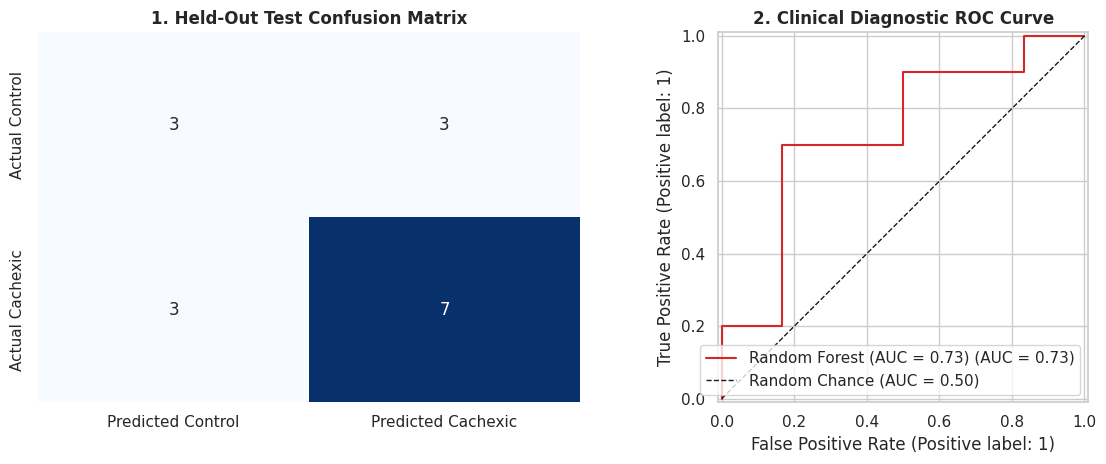

In [5]:
#Held-Out Test Set Evaluation (Confusion Matrix + ROC-AUC Curve)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

# Predict classes and probabilities on the unseen 20% test cohort
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

test_acc = accuracy_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_prob)

print(f"Held-Out Test Accuracy: {test_acc*100:.2f}% | Test ROC-AUC: {test_auc:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Control (0)", "Cachexic (1)"]))

# Plot Confusion Matrix (Left) + ROC Curve (Right)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted Control", "Predicted Cachexic"],
            yticklabels=["Actual Control", "Actual Cachexic"], ax=axes[0])
axes[0].set_title("1. Held-Out Test Confusion Matrix", fontweight="bold")

RocCurveDisplay.from_predictions(y_test, y_prob, name=f"Random Forest (AUC = {test_auc:.2f})",
                                 color="#d62728", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random Chance (AUC = 0.50)")
axes[1].set_title("2. Clinical Diagnostic ROC Curve", fontweight="bold")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("cachexia_ml_evaluation.png", dpi=300)
plt.show()

,Metabolite,Importance
7,3-Hydroxyisovalerate,0.062414
12,Adipate,0.054532
18,Creatine,0.047531
53,Tryptophan,0.044575
59,myo-Inositol,0.033344
14,Asparagine,0.030333
61,pi-Methylhistidine,0.029177
44,Quinolinate,0.028494
16,Carnitine,0.026624
39,"N,N-Dimethylglycine",0.026115


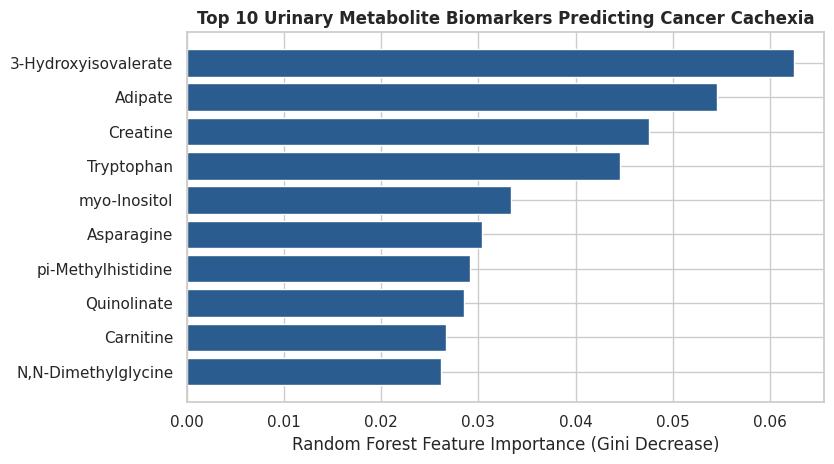

In [6]:
#Top 10 Predictive Metabolite Biomarkers (Feature Importance Analysis
# Extract Gini feature importances to identify which metabolites drive cachexia classification
feat_imp = pd.DataFrame({
    "Metabolite": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

feat_imp.to_csv("cachexia_metabolite_feature_importance.csv", index=False)
top10 = feat_imp.head(10)
display(top10)

plt.figure(figsize=(8.5, 4.8))
plt.barh(top10["Metabolite"][::-1], top10["Importance"][::-1], color="#2b5c8f")
plt.xlabel("Random Forest Feature Importance (Gini Decrease)")
plt.title("Top 10 Urinary Metabolite Biomarkers Predicting Cancer Cachexia", fontweight="bold")
plt.tight_layout()
plt.savefig("cachexia_top10_biomarkers.png", dpi=300)
plt.show()

In [7]:
import os, shutil
from google.colab import drive

drive.mount("/content/drive")
proj_dir = "ML_Clinical_Metabolomics_Cachexia_Biomarkers"
os.makedirs(f"{proj_dir}/results/figures", exist_ok=True)
os.makedirs(f"{proj_dir}/results/tables", exist_ok=True)

shutil.copy("cachexia_ml_evaluation.png", f"{proj_dir}/results/figures/cachexia_ml_evaluation.png")
shutil.copy("cachexia_top10_biomarkers.png", f"{proj_dir}/results/figures/cachexia_top10_biomarkers.png")
shutil.copy("cachexia_metabolite_feature_importance.csv", f"{proj_dir}/results/tables/cachexia_metabolite_feature_importance.csv")

readme_text = f'''# Supervised Machine Learning Biomarker Discovery in Clinical Metabolomics (`Human Cachexia`)

## Overview
End-to-end supervised machine learning pipeline (`scikit-learn`) applied to targeted urinary metabolomics profiles (`human_cachexia.csv`, **77 patients**, **63 quantified metabolites**) to classify **Cancer Cachexia** vs. **Healthy Controls** and rank diagnostic metabolite biomarkers.

## Workflow & Key Results
1. **Leakage-Free Preprocessing (`pandas`, `scikit-learn`):**
   - Encoded clinical phenotypes (`0 = Control`, `1 = Cachexic`) and performed a stratified 80/20 train-test split.
   - Applied `StandardScaler` fit strictly on the training set before transforming held-out test samples.
2. **Model Training & Validation (`RandomForestClassifier`):**
   - Trained a 100-tree Random Forest classifier and verified generalizability using **5-Fold Stratified Cross-Validation** (`Mean CV Accuracy: {cv_acc.mean()*100:.2f}%`, `Mean CV ROC-AUC: {cv_auc.mean():.3f}`).
   - Evaluated on the unseen 20% test cohort (`Test Accuracy: {test_acc*100:.2f}%`, `Test ROC-AUC: {test_auc:.3f}`).
3. **Biomarker Feature Importance:**
   - Ranked all 63 metabolites by Gini importance to pinpoint the primary metabolic drivers of muscle-wasting cachexia.

## Repository Structure
- `03_Clinical_Metabolomics_ML_Cachexia_Biomarkers.ipynb`
- `README.md`
- `results/figures/cachexia_ml_evaluation.png`
- `results/figures/cachexia_top10_biomarkers.png`
- `results/tables/cachexia_metabolite_feature_importance.csv`
'''

with open(f"{proj_dir}/README.md", "w") as f:
    f.write(readme_text)

drive_dest = f"/content/drive/MyDrive/{proj_dir}"
shutil.copytree(proj_dir, drive_dest, dirs_exist_ok=True)
print("Saved Project 3 to Google Drive:", os.listdir(drive_dest))

Mounted at /content/drive
Saved Project 3 to Google Drive: ['results', 'README.md']
